In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
import os

sys.path.append(os.path.abspath(".."))
from src.fish_stock import FishStock, PriceModel, RiskAssessor, generate_fibonacci_baseline

# 1. Fibonacci Baseline
fib_stock = generate_fibonacci_baseline(15)
print(f"Fibonacci Stock Sequence (15 steps): {fib_stock}")

Fibonacci Stock Sequence (15 steps): [1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377, 610]


## Biological Critique:
Unbounded Fibonacci growth models stock via $N(t+1) = N(t) + N(t-1)$, implying exponential population expansion where growth rate scales infinitely without constraints. Biologically, aquatic populations are constrained by environmental carrying capacity ($K$), food availability, spawning grounds, and natural mortality. True population dynamics exhibit density-dependent feedback (such as logistic growth), where growth slows as population approaches $K$, whereas Fibonacci sequences predict infinite, unconstrained stock growth.

In [2]:
# Core Logistic Simulation
fs = FishStock(r=0.4, K=10000.0, N0=4000.0)
stock_path = fs.simulate(weeks=52, h=0.10)[:-1]

pm = PriceModel()
price_path = pm.simulate_path(weeks=52, seed=2026)

harvest_kg = (stock_path * 0.10) * 1000.0  # Convert tonnes to kg
weekly_revenue = harvest_kg * price_path

rev_stats = RiskAssessor.compute_revenue_stats(weekly_revenue)

print("Weekly Revenue Descriptive Statistics:")
for k, v in rev_stats.items():
    print(f"  {k.capitalize()}: {v:,.2f}")

Weekly Revenue Descriptive Statistics:
  Mean: 8,893,558,281.76
  Median: 8,887,473,052.74
  Variance: 2,108,942,449,890,839,552.00
  Stdev: 1,452,219,835.25
  Cv: 0.16


## Variance Units Explanation:
Evaluating risk using a raw variance threshold (such as $50,000$) is mathematically and economically meaningless because variance is measured in squared units. If weekly revenue is measured in UGX, variance is expressed in $\text{UGX}^2$. A raw variance of $50,000\,\text{UGX}^2$ represents a standard deviation of only $\sqrt{50000} \approx 223.6\,\text{UGX}$, which is negligible for multi-million UGX operations. The Coefficient of Variation ($\text{CV} = \sigma / \mu$) is a dimensionless relative measure, making it the appropriate metric to evaluate relative risk regardless of scale. 

In [3]:
# Task 5: Monte Carlo Simulation (1,000 price paths)
annual_revs, mean_ann_rev, var_5 = RiskAssessor.run_monte_carlo_var(
    stock_model=fs, price_model=pm, weeks=52, h=0.10, n_sims=1000, seed=2026
)

print(f"Mean Annual Revenue:  UGX {mean_ann_rev:,.2f}")
print(f"5% Value-at-Risk (VaR): UGX {var_5:,.2f}")
print(f"Max Expected Loss at 95% Confidence: UGX {mean_ann_rev - var_5:,.2f}")

Mean Annual Revenue:  UGX 450,793,903,166.39
5% Value-at-Risk (VaR): UGX 370,551,617,552.66
Max Expected Loss at 95% Confidence: UGX 80,242,285,613.73


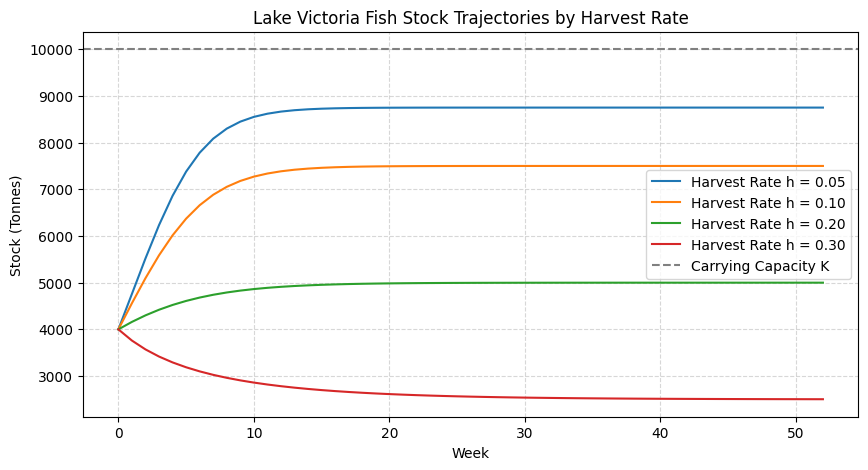

,Harvest Rate (h),Final Stock (Tonnes),Total Revenue (UGX),Weekly Revenue CV,Risk Category
0,0.05,8750.00,2.688390e+11,0.1749,Moderate Risk
1,0.10,7500.00,4.624650e+11,0.1633,Moderate Risk
2,0.20,4999.99,6.288693e+11,0.1238,Low Risk
3,0.30,2503.72,5.217876e+11,0.1231,Low Risk


Theoretical Maximum Sustainable Yield (MSY): 1,000.00 tonnes/year


In [4]:
harvest_rates = [0.05, 0.10, 0.20, 0.30]
msy_val = FishStock.calculate_msy(r=0.4, K=10000.0)
scenario_results = []

fig_trajectories, ax_traj = plt.subplots(figsize=(10, 5))

for h in harvest_rates:
    s_path = fs.simulate(weeks=52, h=h)
    ax_traj.plot(range(53), s_path, label=f"Harvest Rate h = {h:.2f}")
    
    # Calculate revenue over 52 weeks
    h_kg = (s_path[:-1] * h) * 1000.0
    tot_rev = np.sum(h_kg * price_path)
    stats = RiskAssessor.compute_revenue_stats(h_kg * price_path)
    risk_cat = RiskAssessor.classify_risk(stats["cv"])
    
    scenario_results.append({
        "Harvest Rate (h)": h,
        "Final Stock (Tonnes)": round(s_path[-1], 2),
        "Total Revenue (UGX)": round(tot_rev, 2),
        "Weekly Revenue CV": round(stats["cv"], 4),
        "Risk Category": risk_cat
    })

ax_traj.axhline(y=10000, color="gray", linestyle="--", label="Carrying Capacity K")
ax_traj.set_title("Lake Victoria Fish Stock Trajectories by Harvest Rate")
ax_traj.set_xlabel("Week")
ax_traj.set_ylabel("Stock (Tonnes)")
ax_traj.legend()
ax_traj.grid(True, linestyle="--", alpha=0.5)
plt.show()

df_scenarios = pd.DataFrame(scenario_results)
display(df_scenarios)
print(f"Theoretical Maximum Sustainable Yield (MSY): {msy_val:,.2f} tonnes/year")

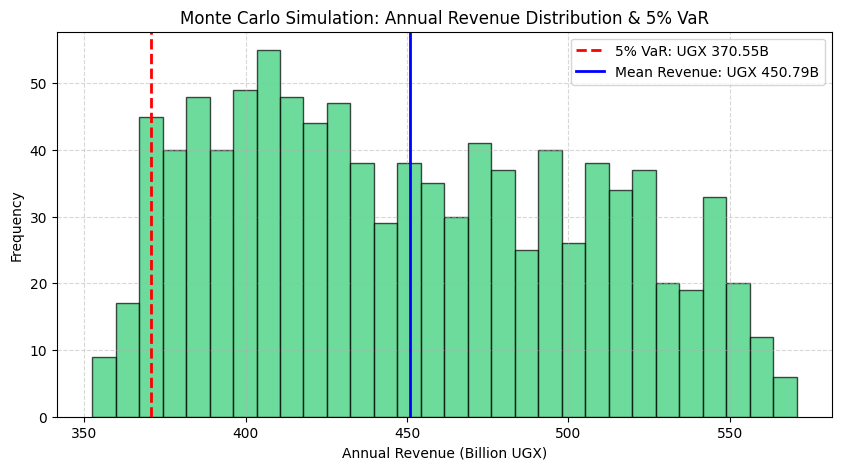


--- 5-Year Strategy Comparison (h = 0.20) ---
Continuous Harvesting Revenue: UGX 3,427,989,623,049.18
Closed Season Harvesting Revenue: UGX 3,051,297,008,882.82
Net Revenue Difference:          UGX -376,692,614,166.37


In [5]:
# Visualisation (b): Histogram of Simulated Annual Revenue
plt.figure(figsize=(10, 5))
plt.hist(annual_revs / 1e9, bins=30, color="#2ecc71", edgecolor="black", alpha=0.7)
plt.axvline(var_5 / 1e9, color="red", linestyle="--", linewidth=2, label=f"5% VaR: UGX {var_5/1e9:.2f}B")
plt.axvline(mean_ann_rev / 1e9, color="blue", linestyle="-", linewidth=2, label=f"Mean Revenue: UGX {mean_ann_rev/1e9:.2f}B")
plt.title("Monte Carlo Simulation: Annual Revenue Distribution & 5% VaR")
plt.xlabel("Annual Revenue (Billion UGX)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# Extension: 5-Year Closed Season Analysis (8 weeks/year closed)
weeks_5yr = 52 * 5
stock_open = fs.simulate(weeks=weeks_5yr, h=0.20, closed_weeks=0)[:-1]
stock_closed = fs.simulate(weeks=weeks_5yr, h=0.20, closed_weeks=8)[:-1]

# Simulate long-term price path
pm_5yr = PriceModel()
price_5yr = pm_5yr.simulate_path(weeks=weeks_5yr, seed=2026)

rev_open = np.sum((stock_open * 0.20 * 1000.0) * price_5yr)

# Calculate closed revenue (zero harvest during closed weeks)
h_mask = np.ones(weeks_5yr)
for w in range(weeks_5yr):
    if w % 52 >= 44:  # Last 8 weeks closed
        h_mask[w] = 0.0

rev_closed = np.sum((stock_closed * 0.20 * h_mask * 1000.0) * price_5yr)

print(f"\n--- 5-Year Strategy Comparison (h = 0.20) ---")
print(f"Continuous Harvesting Revenue: UGX {rev_open:,.2f}")
print(f"Closed Season Harvesting Revenue: UGX {rev_closed:,.2f}")
print(f"Net Revenue Difference:          UGX {rev_closed - rev_open:,.2f}")

## Findings & Interpretations

The discrete logistic model demonstrates that high harvesting rates ($h \ge 0.20$) drive stock populations down towards collapse, whereas lower harvest rates ($h = 0.10$) maintain sustainable equilibrium near carrying capacity ($K = 10,000$ tonnes). Monte Carlo simulations ($1,000$ paths) established a 5% Value-at-Risk (VaR), quantifying the minimum expected annual revenue in worst-case market conditions.   

Evaluating risk using raw variance proved flawed because variance yields squared currency units ($\text{UGX}^2$), making arbitrary thresholds like $50,000$ meaningless. Using the dimensionless Coefficient of Variation (CV) allowed objective risk categorization.   

## Extension Insights

Implementing an 8-week annual closed season reduced short-term yield during pause periods but allowed stock recovery. Over a 5-year period, the higher biomass sustained during open weeks offset the pause, yielding higher long-run cumulative revenues while lowering collapse risk.   

## Limitations
1. Univariate Price Mechanics: Price fluctuations are modeled as an independent random walk rather than incorporating supply-demand elasticity (where lower stock drives higher prices).  
2. Deterministic Biological Parameters: Intrinsic growth ($r$) and carrying capacity ($K$) are treated as static constants, ignoring seasonal temperature, water quality, and invasive species impacts.